# 05 — Georgia ECG Anomalies, Error Labels Catalog & Waveform Galleries

This notebook summarizes and visualizes the **18-flag per-record error & data-quality catalog** (`georgia_ecg/quality/error_labels.csv`, generated by `georgia_ecg/quality/generate_error_labels.py`) across all `10,344` Georgia 12-Lead ECG records:

### Four Actionable Severity Tiers
- **`0_clean`** (`keep`): Zero error or warning flags.
- **`1_minor_warning`** (`keep_with_cleaning`): Missing `age`/`sex`, pediatric `age < 18`, unscored-only CinC 2020 labels, or `>0.5 mV` DC baseline offset.
- **`2_moderate_anomaly`** (`review_or_downweight`): Non-10s recording duration, invalid age (`<=0` or `>100`), unmapped SNOMED code, `NSR` + arrhythmia conflict, rhythm/HR mismatch, or excessive baseline wander / HF noise.
- **`3_severe_error`** (`exclude`): Missing/corrupt file, non-standard fs/leads, empty `Dx`, `NaN`/`Inf`, flatline lead (`>=500 ms`), `>10 mV` extreme rail spike, or Einthoven/Goldberger limb-physics violation.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import wfdb

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 120, "savefig.bbox": "tight"})

_cwd = Path.cwd().resolve()
for _candidate in [_cwd, _cwd.parent, _cwd.parent.parent]:
    if (_candidate / "georgia_ecg" / "quality" / "error_labels.csv").exists():
        REPO_ROOT = _candidate
        break
else:
    raise FileNotFoundError(f"Could not locate georgia_ecg/quality/error_labels.csv from {_cwd}")

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from georgia_ecg import GeorgiaECGDataset

GEORGIA_DIR = REPO_ROOT / "georgia_ecg"
DATA_DIR = GEORGIA_DIR / "data"
LEADS = GeorgiaECGDataset.LEADS

df = pd.read_csv(GEORGIA_DIR / "quality" / "error_labels.csv", index_col="record_id")
df["snomed_codes"] = df["snomed_codes"].fillna("")
df["label_names"] = df["label_names"].fillna("")
df["error_tags"] = df["error_tags"].fillna("")
df["sex"] = df["sex"].fillna("")
print(f"Loaded {len(df):,} Georgia 12-Lead ECG records from error_labels.csv")

flag_cols = [c for c in df.columns if c.startswith("err_")]

def domain_of(col: str) -> str:
    if col.startswith(("err_file_", "err_hdr_")):
        return "1. File / Header"
    if col.startswith(("err_age_", "err_sex_")):
        return "2. Demographics"
    if col.startswith(("err_dx_", "err_rhythm_")):
        return "3. SNOMED-CT Label"
    return "4. 500 Hz Waveform"

summary = pd.DataFrame([
    {
        "flag": c, "domain": domain_of(c),
        "count": int(df[c].sum()),
        "pct_of_10344": round(float(df[c].mean() * 100), 2),
    }
    for c in flag_cols
]).sort_values(["domain", "count"], ascending=[True, False])
display(summary)

tier_summary = df.groupby(["severity_tier", "recommended_action"]).size().rename("count").reset_index()
tier_summary["pct"] = (tier_summary["count"] / len(df) * 100).round(2)
display(tier_summary)

Loaded 10,344 Georgia 12-Lead ECG records from error_labels.csv


,flag,domain,count,pct_of_10344
1,err_hdr_nonstandard_duration,1. File / Header,52,0.50
0,err_file_missing_or_corrupt,1. File / Header,10,0.10
2,err_hdr_nonstandard_fs_or_leads,1. File / Header,0,0.00
3,err_age_missing,2. Demographics,77,0.74
5,err_age_pediatric,2. Demographics,3,0.03
4,err_age_invalid_or_sentinel,2. Demographics,0,0.00
6,err_sex_missing_or_unknown,2. Demographics,0,0.00
9,err_dx_no_scored_cinc2020,3. SNOMED-CT Label,885,8.56
11,err_rhythm_hr_mismatch,3. SNOMED-CT Label,471,4.55
7,err_dx_empty,3. SNOMED-CT Label,0,0.00


,severity_tier,recommended_action,count,pct
0,0_clean,keep,8770,84.78
1,1_minor_warning,keep_with_cleaning,941,9.10
2,2_moderate_anomaly,review_or_downweight,584,5.65
3,3_severe_error,exclude,49,0.47


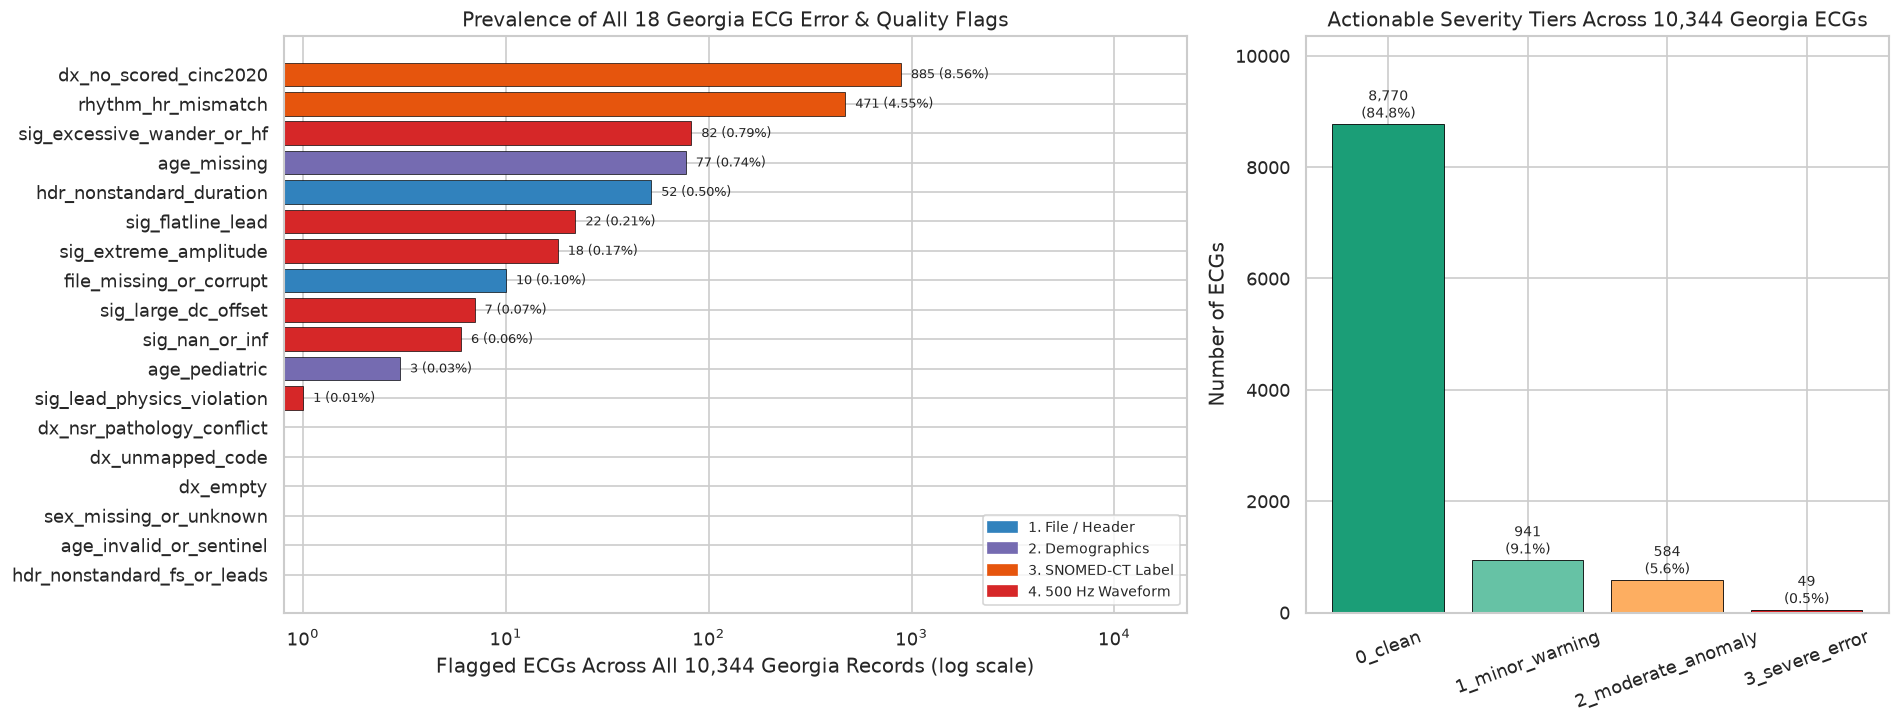

In [2]:
from matplotlib.patches import Patch

fig, axes = plt.subplots(1, 2, figsize=(16, 6.2), gridspec_kw={"width_ratios": [1.55, 1]})

plot_tbl = summary.sort_values("count", ascending=True)
dom_pal = {
    "1. File / Header": "#3182bd",
    "2. Demographics": "#756bb1",
    "3. SNOMED-CT Label": "#e6550d",
    "4. 500 Hz Waveform": "#d62728",
}
axes[0].barh(plot_tbl["flag"].str.replace("^err_", "", regex=True), plot_tbl["count"], color=[dom_pal[d] for d in plot_tbl["domain"]], edgecolor="black", lw=0.4)
axes[0].set_xscale("log")
axes[0].set_xlabel("Flagged ECGs Across All 10,344 Georgia Records (log scale)")
axes[0].set_title("Prevalence of All 18 Georgia ECG Error & Quality Flags")
for i, (cnt, pct) in enumerate(zip(plot_tbl["count"], plot_tbl["pct_of_10344"])):
    if cnt > 0:
        axes[0].text(cnt * 1.12, i, f"{cnt:,} ({pct:.2f}%)", va="center", fontsize=8)
axes[0].set_xlim(0.8, len(df) * 2.2)
axes[0].legend(handles=[Patch(color=v, label=k) for k, v in dom_pal.items()], loc="lower right", fontsize=8.5)

tier_vc = df["severity_tier"].value_counts().sort_index()
tier_colors = ["#1b9e77", "#66c2a5", "#fdae61", "#d7191c"]
axes[1].bar(tier_vc.index, tier_vc.values, color=tier_colors, edgecolor="black", lw=0.5)
axes[1].set_ylabel("Number of ECGs")
axes[1].set_title("Actionable Severity Tiers Across 10,344 Georgia ECGs")
axes[1].tick_params(axis="x", rotation=20)
for i, v in enumerate(tier_vc.values):
    axes[1].text(i, v + 120, f"{v:,}\n({v/len(df)*100:.1f}%)", ha="center", fontsize=8.5)
axes[1].set_ylim(0, tier_vc.max() * 1.18)

plt.tight_layout()
plt.show()

## 5.1 Waveform Galleries of Georgia ECG Anomalies & Errors

Visualizing real `500 Hz` Georgia ECG waveforms directly from `georgia_ecg/quality/error_labels.csv` across severe waveform corruptions (`flatline`, `>10 mV` rail spikes, Einthoven limb-physics violations, excessive wander / `60 Hz` hum) and clinical/header anomalies (`non-10s` truncated recordings, `NSR` + arrhythmia conflicts, rhythm/HR mismatches, and large DC offsets).

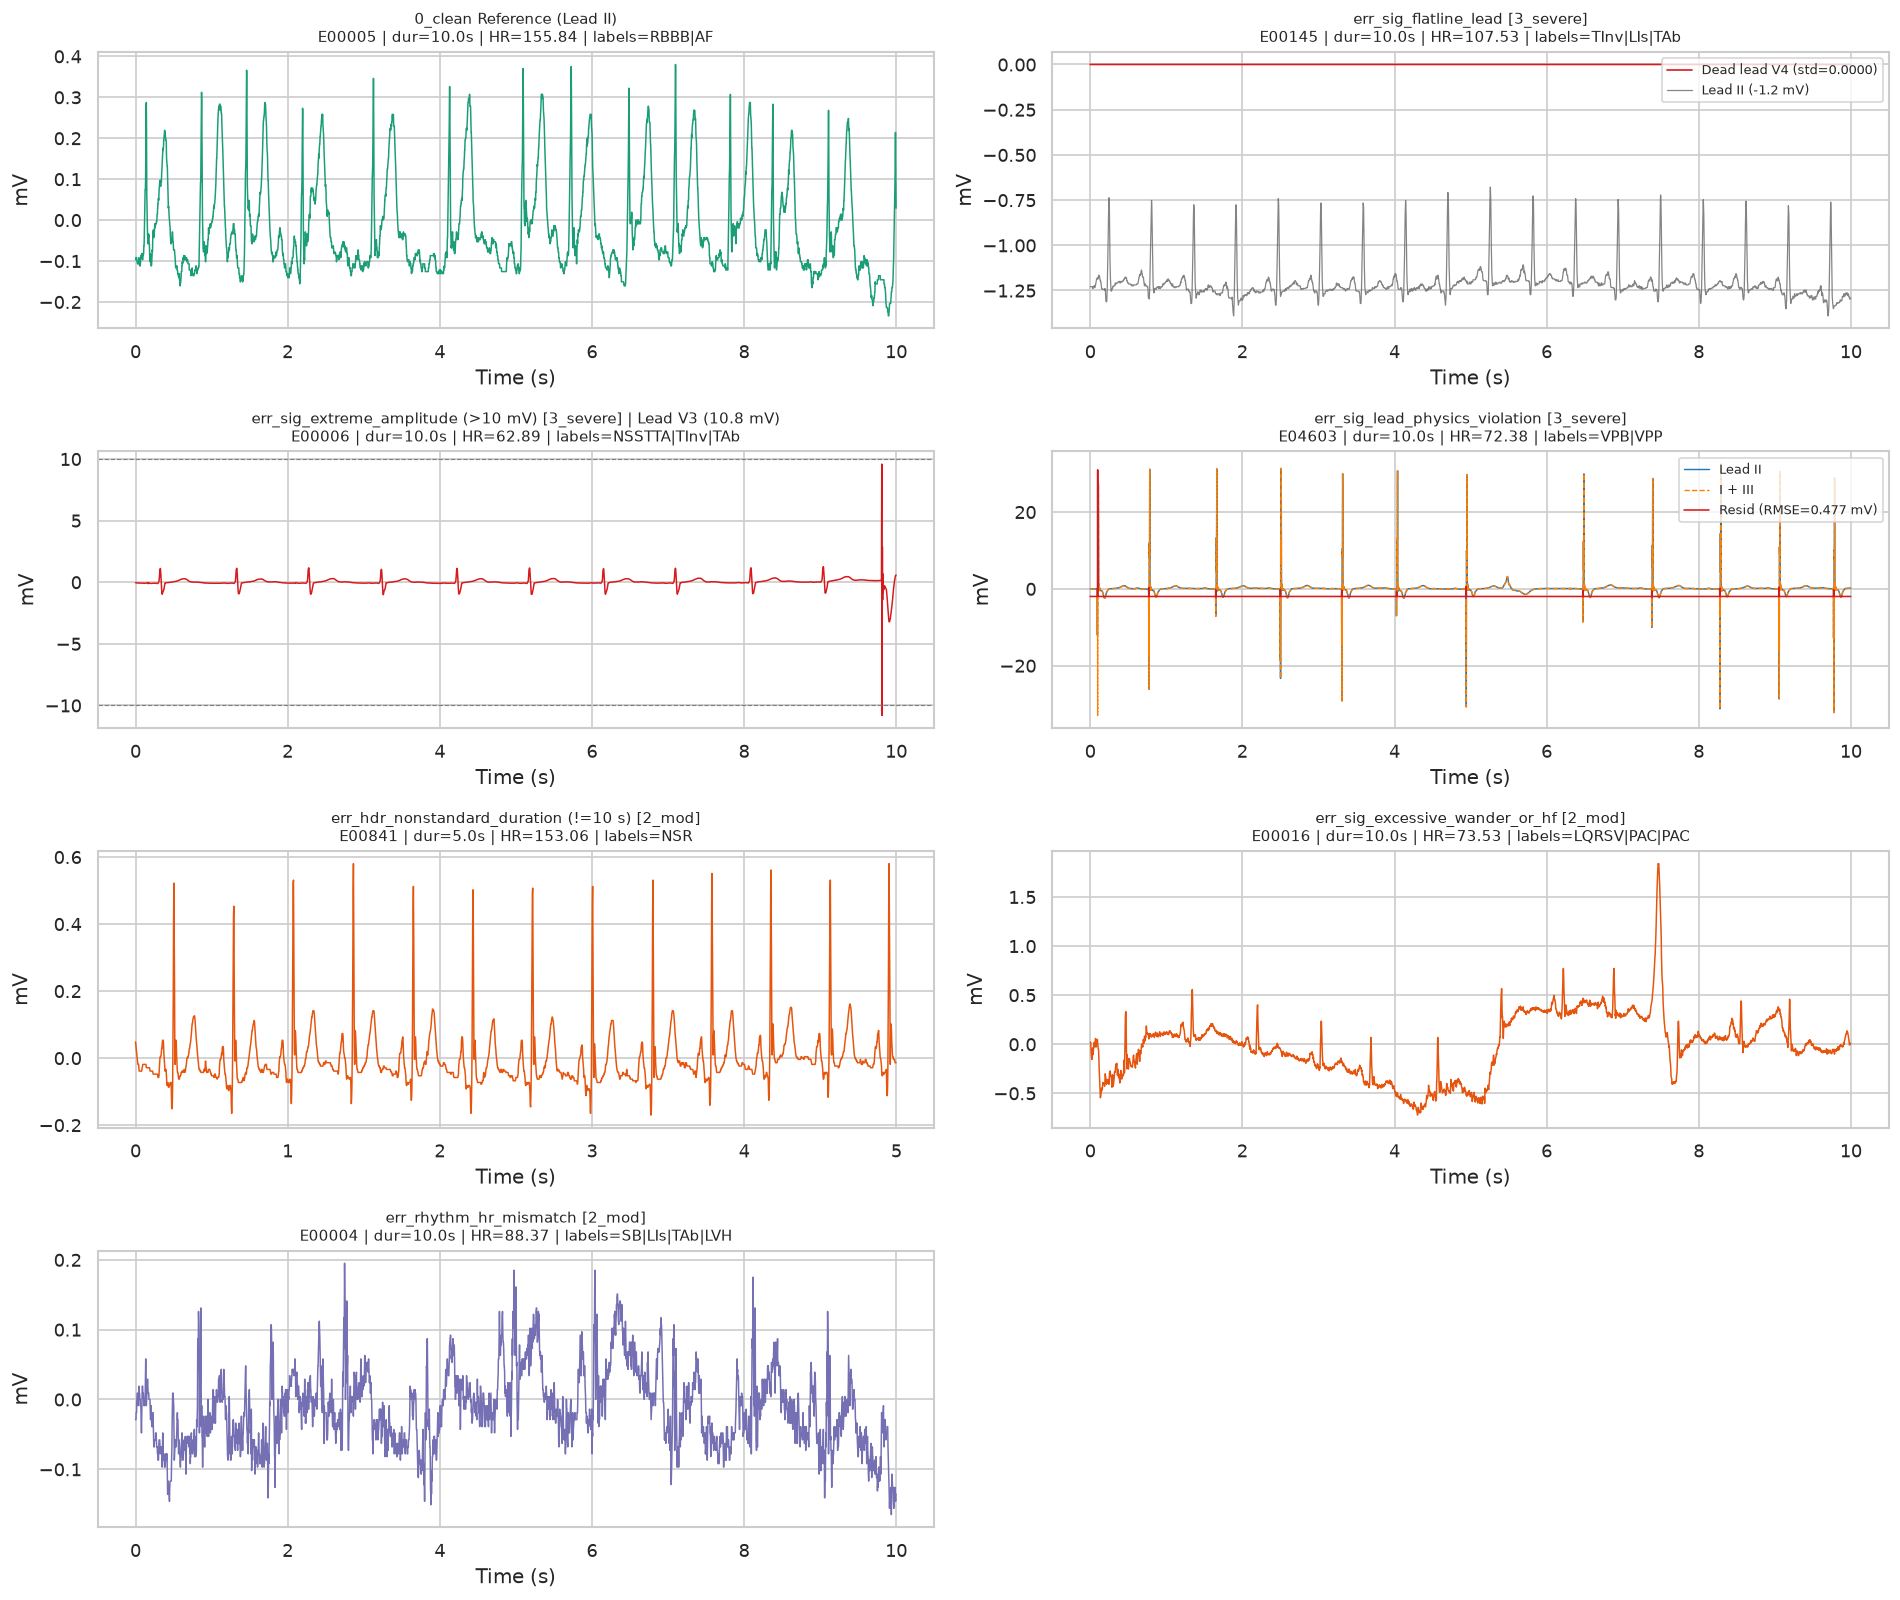

In [3]:
valid_df = df[df["err_file_missing_or_corrupt"] == 0]

def pick_id(mask: pd.Series) -> str | None:
    sub = valid_df.index[mask]
    return str(sub[0]) if len(sub) > 0 else None

def load_rec(rid: str) -> np.ndarray:
    sig, _ = wfdb.rdsamp(str(DATA_DIR / valid_df.loc[rid, "record_path"]))
    return np.nan_to_num(sig)

cases = [
    ("0_clean Reference (Lead II)", pick_id(valid_df["severity_tier"] == "0_clean"), "clean"),
    ("err_sig_flatline_lead [3_severe]", pick_id(valid_df["err_sig_flatline_lead"] == 1), "flat"),
    ("err_sig_extreme_amplitude (>10 mV) [3_severe]", pick_id(valid_df["err_sig_extreme_amplitude"] == 1), "spike"),
    ("err_sig_lead_physics_violation [3_severe]", pick_id(valid_df["err_sig_lead_physics_violation"] == 1), "physics"),
    ("err_hdr_nonstandard_duration (!=10 s) [2_mod]", pick_id(valid_df["err_hdr_nonstandard_duration"] == 1), "dur"),
    ("err_sig_excessive_wander_or_hf [2_mod]", pick_id(valid_df["err_sig_excessive_wander_or_hf"] == 1), "wander"),
    ("err_dx_nsr_pathology_conflict [2_mod]", pick_id(valid_df["err_dx_nsr_pathology_conflict"] == 1), "conflict"),
    ("err_rhythm_hr_mismatch [2_mod]", pick_id(valid_df["err_rhythm_hr_mismatch"] == 1), "hr"),
]
cases = [(lbl, rid, mode) for lbl, rid, mode in cases if rid is not None]

fig, axes = plt.subplots(4, 2, figsize=(16, 13.5))
axes = axes.ravel()

for ax, (title, rid, mode) in zip(axes, cases):
    s = load_rec(rid)
    t = np.arange(s.shape[0]) / 500.0
    row = valid_df.loc[rid]
    if mode == "flat":
        l_idx = int(np.argmin(s.std(axis=0)))
        ax.plot(t, s[:, l_idx], color="#d7191c", lw=1.0, label=f"Dead lead {LEADS[l_idx]} (std={s[:, l_idx].std():.4f})")
        ax.plot(t, s[:, 1] - 1.2, color="#666666", lw=0.75, alpha=0.8, label="Lead II (-1.2 mV)")
        ax.legend(fontsize=7.5, loc="upper right")
    elif mode == "spike":
        l_idx = int(np.argmax(np.abs(s).max(axis=0)))
        ax.plot(t, s[:, l_idx], color="#d7191c", lw=0.9)
        ax.axhline(10, color="gray", ls="--", lw=0.7); ax.axhline(-10, color="gray", ls="--", lw=0.7)
        title += f" | Lead {LEADS[l_idx]} ({np.abs(s[:, l_idx]).max():.1f} mV)"
    elif mode == "physics":
        recon = s[:, 0] + s[:, 2]
        resid = s[:, 1] - recon
        ax.plot(t, s[:, 1], color="#1f78b4", lw=0.85, label="Lead II")
        ax.plot(t, recon, color="#ff7f00", lw=0.85, ls="--", label="I + III")
        ax.plot(t, resid - 2.0, color="#d7191c", lw=0.95, label=f"Resid (RMSE={row['einthoven_rmse_mv']:.3f} mV)")
        ax.legend(fontsize=7.5, loc="upper right")
    else:
        col_c = "#1b9e77" if mode == "clean" else "#e6550d" if mode in ("wander", "dur") else "#7570b3"
        ax.plot(t, s[:, 1], color=col_c, lw=0.9)
    ax.set_title(f"{title}\n{rid} | dur={row['duration_s']}s | HR={row['est_hr_bpm']} | labels={row['label_names']}", fontsize=8.8)
    ax.set_ylabel("mV")
    ax.set_xlabel("Time (s)")

for ax in axes[len(cases):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 5.2 Filtering Georgia ECG Directly via `GeorgiaECGDataset`

In [4]:
ds_raw      = GeorgiaECGDataset()
ds_no_sev   = GeorgiaECGDataset(max_error_severity=2, load_error_labels=True)
ds_clean_10 = GeorgiaECGDataset(max_error_severity=1, exclude_error_flags=["err_hdr_nonstandard_duration"])
ds_gold     = GeorgiaECGDataset(max_error_severity=0)

sample0 = ds_no_sev[0]
print("Sample[0] resolved label_names:", sample0["label_names"])
print("Sample[0] error_labels summary:", sample0["error_labels"]["severity_tier"], "|", sample0["error_labels"]["error_tags"])

cmp = pd.DataFrame([
    {"Configuration": "Default GeorgiaECGDataset() [raw RECORDS]", "Num Records": len(ds_raw)},
    {"Configuration": "max_error_severity=2 (exclude 3_severe_error)", "Num Records": len(ds_no_sev)},
    {"Configuration": "max_error_severity=1 (clean + minor warnings, strict 10s)", "Num Records": len(ds_clean_10)},
    {"Configuration": "max_error_severity=0 (strictly 0-flag gold subset)", "Num Records": len(ds_gold)},
])
display(cmp)

Sample[0] resolved label_names: ['NSR']
Sample[0] error_labels summary: 1_minor_warning | ['age_missing']


,Configuration,Num Records
0,Default GeorgiaECGDataset() [raw RECORDS],10344
1,max_error_severity=2 (exclude 3_severe_error),10295
2,"max_error_severity=1 (clean + minor warnings, ...",9711
3,max_error_severity=0 (strictly 0-flag gold sub...,8770
